In [2]:
import pandas as pd
import os
from os.path import join
import matplotlib.pyplot as plt
from matplotlib import rc
plt.rcParams["font.family"] = "Times New Roman"
import numpy as np
import scipy.stats as stats
from config import DATA_DIR, BASE_DIR

In [3]:
def compute_average_and_ci(data, confidence=0.95):
    # Convert to numpy array
    data = np.array(data)
    
    # Calculate mean
    mean = np.mean(data)
    
    # Calculate standard error
    se = stats.sem(data)
    
    # Calculate margin of error
    ci = se * stats.t.ppf((1 + confidence) / 2., len(data) - 1)
    
    return mean, ci

### Load blocking relationships

In [4]:
# how many moderated instances are in our instance data
df = pd.read_parquet(join(BASE_DIR, "server_level_moderation", "blocking_relationships.parquet"))
df.head()

,name,moderated_instance,reason,type
0,mastodon.xyz,detroitriotcity.com,Reason not available,Limited
1,mastodon.xyz,kinky.business,NSFW-focused instance,Limited
2,mastodon.xyz,pawoo.net,Lots of public unmoderated NSFW content,Limited
3,mastodon.xyz,switter.at,NSFW-focused instance,Limited
4,mastodon.xyz,bird.makeup,Mass automated accounts,Suspended


In [5]:
df['moderated_instance'].value_counts(dropna=False).to_dict()

{'poa.st': 752,
 'pawoo.net': 687,
 'freespeechextremist.com': 665,
 'baraag.net': 645,
 'detroitriotcity.com': 633,
 'bae.st': 624,
 'nicecrew.digital': 563,
 'shitposter.club': 518,
 'spinster.xyz': 513,
 'gameliberty.club': 513,
 'noagendasocial.com': 509,
 'pieville.net': 504,
 'yggdrasil.social': 490,
 'beefyboys.win': 476,
 'brighteon.social': 476,
 'varishangout.net': 458,
 'kiwifarms.cc': 455,
 'gab.com': 454,
 'cum.salon': 450,
 'ryona.agency': 443,
 'gleasonator.com': 439,
 'iddqd.social': 430,
 'activitypub-troll.cf': 416,
 'eientei.org': 411,
 'freeatlantis.com': 406,
 'seal.cafe': 394,
 'cawfee.club': 387,
 'eveningzoo.club': 385,
 'gab.ai': 384,
 'freak.university': 366,
 'nnia.space': 365,
 'truthsocial.co.in': 361,
 'mugicha.club': 360,
 'chudbuds.lol': 360,
 'lolison.top': 345,
 'leafposter.club': 343,
 'clubcyberia.co': 340,
 'freecumextremist.com': 340,
 'mastinator.com': 338,
 'threads.net': 336,
 'misskey-forkbomb.cf': 334,
 'poster.place': 332,
 'repl.co': 323,
 '

In [6]:
# number of blocking-blocked relations
df.shape

(153966, 4)

In [7]:
# number of unique moderated instances
df["moderated_instance"].nunique()

15708

In [8]:
df.groupby("moderated_instance").size().sort_values(ascending=False)

moderated_instance
poa.st                            752
pawoo.net                         687
freespeechextremist.com           665
baraag.net                        645
detroitriotcity.com               633
                                 ... 
https:noagendasocial.com            1
https:p*.*******.*etwork            1
https:pl*****.*********rry.xyz      1
https:pl*****.*********the.biz      1
mastodont.social                    1
Length: 15708, dtype: int64

In [9]:
# instances modertaed by mastodon.social
u = df[df["name"]=="mastodon.social"]["moderated_instance"].unique()
df[df["name"]=="mastodon.social"]["moderated_instance"].nunique()

271

In [10]:
df.moderated_instance.value_counts().head(10)

moderated_instance
poa.st                     752
pawoo.net                  687
freespeechextremist.com    665
baraag.net                 645
detroitriotcity.com        633
bae.st                     624
nicecrew.digital           563
shitposter.club            518
spinster.xyz               513
gameliberty.club           513
Name: count, dtype: int64

In [11]:
# where are the instances moderated by mastodon.social located in the overall ranking?
positions = df.moderated_instance.value_counts().index.get_indexer(u)

In [12]:
sorted([int(i) for i in positions])

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 32,
 34,
 35,
 36,
 37,
 38,
 40,
 41,
 42,
 43,
 45,
 47,
 49,
 50,
 51,
 52,
 54,
 55,
 57,
 60,
 64,
 66,
 70,
 73,
 74,
 75,
 76,
 77,
 78,
 79,
 82,
 83,
 84,
 89,
 90,
 92,
 94,
 97,
 99,
 100,
 102,
 103,
 104,
 105,
 106,
 108,
 109,
 126,
 130,
 131,
 132,
 134,
 135,
 137,
 142,
 143,
 145,
 146,
 147,
 157,
 165,
 167,
 169,
 179,
 183,
 195,
 197,
 200,
 201,
 208,
 214,
 218,
 220,
 232,
 233,
 240,
 244,
 254,
 256,
 266,
 268,
 271,
 291,
 292,
 330,
 336,
 337,
 348,
 361,
 371,
 384,
 388,
 394,
 398,
 408,
 413,
 418,
 425,
 450,
 452,
 463,
 468,
 469,
 472,
 478,
 484,
 485,
 486,
 488,
 495,
 503,
 508,
 510,
 514,
 515,
 517,
 525,
 528,
 536,
 541,
 548,
 549,
 556,
 559,
 561,
 566,
 568,
 574,
 586,
 597,
 599,
 605,
 607,
 614,
 616,
 618,
 629,
 630,
 631,
 635,
 641,
 645,
 655,
 667,
 670,
 671,
 679,
 684,
 690,


In [13]:
df['reason'] = df['reason'].apply(lambda x: x.lower())

In [14]:
df['reason'].value_counts(dropna=False).to_dict()

{'reason not available': 78699,
 'n/a': 8191,
 '': 6971,
 'motivo non indicado.': 1346,
 'grund unbekannt': 1338,
 'hate speech': 1285,
 'problematische inhalte': 1176,
 'we do not federate with facebook/meta': 1130,
 'spam': 1036,
 '사유를 밝히지 않음': 772,
 'harassment': 760,
 'transphobia': 729,
 'racism': 571,
 'third-party bots': 558,
 'crosspost bot, bsl': 528,
 'imported:': 491,
 'birdsitelive/bot': 453,
 'actively federates with the usual suspects.': 446,
 'oliphant unified blocklist - tier 0': 441,
 'oliphant t0 unified blocklist.': 439,
 'oliphant/blocklist/tier1': 432,
 'oliphant unified tier0 blocklist': 416,
 'no reason given': 416,
 'taken from a.rathersafe.space': 408,
 'alt-fedi': 407,
 'pedophilia': 406,
 'imported': 384,
 'fediblock': 383,
 'chan eil an t-adhbhar ga thoirt seachad': 367,
 'tech.lgbt import': 367,
 'inappropriate content': 342,
 'twitter crossposter': 314,
 'we do not openly federate with facebook/meta': 282,
 'identity hate': 262,
 'dni': 254,
 'oliphant lis

In [ ]:
instance_df = pd.read_parquet(join(DATA_DIR, "regression_data.parquet"))
instance_df.head()

,name,user_count,status_count,active_users,languages,joined_rules,pleroma,scraped_blocked_domains,has_rules,software,...,automated_tools_bots_true,language_specific_true,spoilers_true,crypto_true,ai_generated_true,scrape_model_training_true,private_no_reg_true,impersonation_true,block_report_mute_true,labeled
0,/,1.0,10.0,nan,"['fr', 'en']",None,nan,[],0,None,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,0.0
1,0.0n.ee,2.0,62.0,nan,['en'],None,{'favicon': 'https://0-s3.0n.ee/rebased-bucket...,[],0,pleroma,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,0.0
2,000000420.xyz,1.0,5.0,nan,['en'],None,{'metadata': {'account_activation_required': T...,[],0,akkoma,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,0.0
3,0371.uk,1.0,103.0,1.0,['en'],None,nan,[],0,mastodon,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,0.0
4,07738135.xyz,1.0,3.0,nan,[],None,nan,[],0,gotosocial,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,0.0


In [16]:
instance_df.shape

(15915, 142)

In [17]:
instance_df.columns

Index(['name', 'user_count', 'status_count', 'active_users', 'languages',
       'joined_rules', 'pleroma', 'scraped_blocked_domains', 'has_rules',
       'software',
       ...
       'automated_tools_bots_true', 'language_specific_true', 'spoilers_true',
       'crypto_true', 'ai_generated_true', 'scrape_model_training_true',
       'private_no_reg_true', 'impersonation_true', 'block_report_mute_true',
       'labeled'],
      dtype='object', length=142)

In [18]:
instance_list = list(instance_df['name'].unique())

### Proportion of moderated instances in our instance dataset

In [19]:
df['is_in_list'] = df['moderated_instance'].apply(lambda x: 1 if x in instance_list else 0)
# on all edges
df['is_in_list'].value_counts(dropna=False, normalize=True)

is_in_list
0    0.669869
1    0.330131
Name: proportion, dtype: float64

In [20]:
reason_list = ['misinformation',
 'spreading fake news.',
 'conspiracism',
 'conspiracy theories',
 'harmful misinformation',
 'misinformation and conspiracy theories',
 'hate speech; harmful misinformation',
 'covid denialism',
 'conspiracy',
 'conspiracy videos',
 'mì-fhios']

In [21]:
df = df.loc[df['is_in_list']==1]

In [22]:
misinfo_moderating_list = list(df.loc[df['reason'].isin(reason_list)]['name'].unique())
misinfo_moderating_list

['toot.cat',
 'mastodon.sandwich.net',
 'mastodon.art',
 'mastodon.social',
 'djs.social',
 'dice.camp',
 'www.librepunk.club',
 'ifwo.eu',
 'mastodon.online',
 'ailbhean.co-shaoghal.net',
 'aut.social',
 'musicians.today',
 'synapse.cafe',
 'babblebox.net',
 'networker.social',
 'datasci.social',
 'libera.tokyo',
 'toot.krivokuca.dev',
 'akko.wtf',
 'fandom.garden',
 'better.boston',
 'retrochat.online',
 'dosgame.club',
 'camp.smolnet.org',
 'sunny.garden',
 'fediverse.antho.dev',
 'mstdn.social',
 'r2.do',
 'toki.social',
 'synthwave.social',
 'deacon.social',
 'writeout.ink',
 'mastodon.mathys.social',
 'slut.town',
 'mastodon.koehlercode.dev',
 'g33ks.coffee',
 'howdee.social',
 'akkoma.sandhill.social',
 'witches.rest',
 'mastd.dev',
 'flipboard.social',
 'social.flipboard.com',
 'koehlercode.dev',
 'toot.foundation',
 'social.trout.garden',
 'dope.bz',
 'kult.dumb.land',
 'smilodon.chatslibres.com',
 'void.lgbt',
 'scottodon.com',
 'kasumi.loliimoutolove.com',
 'thewired.wtf']

In [23]:
misinfo_moderated_list = list(df.loc[df['reason'].isin(reason_list)]['moderated_instance'].unique())

In [24]:
len(misinfo_moderating_list)

52

In [25]:
len(misinfo_moderated_list)

75

### Load misinformation toot data

In [26]:
toots_df = pd.read_parquet(join(DATA_DIR, '13-toots_quality.parquet'))
toots_df.head()

,instance,id,created_at,username,domain,hause_quality
0,social.cthompson.com,111331194292105100,2023-10-31 19:06:49.798000+00:00,108257780827290773,youtube.com,0.375093
1,social.cthompson.com,111331194292105100,2023-10-31 19:06:49.798000+00:00,108257780827290773,youtube.com,0.375093
2,social.cthompson.com,111257622136722059,2023-10-18 19:16:27.779000+00:00,108257780827290773,imgur.com,NaN
3,social.cthompson.com,111257622136722059,2023-10-18 19:16:27.779000+00:00,108257780827290773,imgur.com,NaN
4,social.cthompson.com,111250596765096038,2023-10-17 13:29:49.115000+00:00,108257780827290773,None,NaN


In [27]:
toots_df.shape

(45656084, 6)

In [28]:
# deduplicate posts
toots_df.drop_duplicates(subset=['instance', 'id'], inplace=True)

In [29]:
toots_df =  toots_df[["instance","domain", "hause_quality"]]

In [30]:
toots_df.shape

(13964433, 3)

In [31]:
#drop irrelevant domains
exclude_domains_list = [
    "youtube.com",
    "youtu.be",
    "youtube.be",
    "t.me",
    "yt.be",
    "facebook.com",
    "google.com",
    "yahoo.com",
    "blogspot.com",
    "twitter.com",
    "wordpress.com",
    "medium.com",
    "instagram.com",
    "substack.com",
    "spotify.com",
    "spoti.fi",
    "walmrt.us",
    "walmart.com",
    "tiktok.com",
    "fb.watch",
    "paypal.com",
    "gofundme.com", 
    "linkedin.com",
    "patreon.com",
    "twitch.tv",
    "reddit.com",
    "blog.jp",
    "zoom.us",
    "amazon.com",
    "amazon.ca",
    "amazon.co.jp",
    "amazon.co.uk",
    "dailymotion.com",
    "telegram.org",
    "discord.gg",
    "apple.news",
    "yahoo.com",
    "sankei.com",
    "nordot.app",
    "anonymous-post.mobi",
    "odysee.com",
    "gettr.com"]

In [32]:
# Create a boolean mask where True indicates the domain is in exclude_domains_list
mask = toots_df['domain'].isin(exclude_domains_list)

# Use the mask to set 'hause_quality' to None where the mask is True
toots_df.loc[mask, 'hause_quality'] = None

In [33]:
results_dict = dict()

In [34]:
misinfo_toot_count_dict = dict()

In [35]:
thresholds = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]

In [36]:
for threshold in thresholds:
    misinfo_count = toots_df.loc[toots_df['hause_quality']<threshold].shape[0]
    misinfo_toot_count_dict[threshold] = misinfo_count

In [37]:
misinfo_toot_count_dict

{0.2: 7832,
 0.25: 11386,
 0.3: 26876,
 0.35: 28867,
 0.4: 39650,
 0.45: 46447,
 0.5: 57543}

In [38]:
misinfo_toot_count_dict[0.2]/toots_df.shape[0]

0.0005608534195409151

In [39]:
misinfo_toot_count_dict[0.2]/toots_df[toots_df['hause_quality'].notnull()].shape[0]

0.009968904451512965

In [40]:
misinfo_toot_count_dict[0.5]/toots_df[toots_df['hause_quality'].notnull()].shape[0]


0.07324319060947529

In [41]:
misinfo_toot_count_dict[0.5]/toots_df.shape[0]

0.004120682880572379

In [42]:
misinfo = toots_df[toots_df['hause_quality']<0.2]
misinfo.groupby('domain').size().sort_values(ascending=False).head(20)/misinfo.shape[0]

domain
rumble.com                      0.246170
bitchute.com                    0.175434
thegatewaypundit.com            0.152451
infowars.com                    0.139173
naturalnews.com                 0.036900
americanthinker.com             0.023110
childrenshealthdefense.org      0.015832
newstarget.com                  0.014939
wnd.com                         0.013023
globalresearch.ca               0.012768
banned.video                    0.012002
gellerreport.com                0.010342
theconservativetreehouse.com    0.009065
mercola.com                     0.008938
pravda.ru                       0.008299
imolaoggi.it                    0.007533
technocracy.news                0.007278
neonnettle.com                  0.006129
off-guardian.org                0.005746
gnews.org                       0.005746
dtype: float64

In [43]:
misinfo = toots_df[toots_df['hause_quality']<0.2]

In [44]:
misinfo.groupby('domain').size().sort_values(ascending=False).cumsum()/misinfo.shape[0]

domain
rumble.com                  0.246170
bitchute.com                0.421604
thegatewaypundit.com        0.574055
infowars.com                0.713228
naturalnews.com             0.750128
                              ...   
hereistheevidence.com       0.999489
jesus-is-savior.com         0.999617
collective-evolution.com    0.999745
mediamass.net               0.999872
skeptiko.com                1.000000
Length: 109, dtype: float64

In [45]:
for moderating_server in misinfo_moderating_list:
    print(moderating_server)
    moderating_df = df.loc[df['name']==moderating_server]
    moderated_list = list(moderating_df['moderated_instance'].unique())
    tmp_df = toots_df.loc[toots_df['instance'].isin(moderated_list)]
    share_list = list()
    for threshold in thresholds:
        share_list.append(tmp_df.loc[tmp_df['hause_quality']<threshold].shape[0]/misinfo_toot_count_dict[threshold])
    results_dict[moderating_server]= compute_average_and_ci(share_list)

toot.cat
mastodon.sandwich.net
mastodon.art
mastodon.social
djs.social
dice.camp
www.librepunk.club
ifwo.eu
mastodon.online
ailbhean.co-shaoghal.net
aut.social
musicians.today
synapse.cafe
babblebox.net
networker.social
datasci.social
libera.tokyo
toot.krivokuca.dev
akko.wtf
fandom.garden
better.boston
retrochat.online
dosgame.club
camp.smolnet.org
sunny.garden
fediverse.antho.dev
mstdn.social
r2.do
toki.social
synthwave.social
deacon.social
writeout.ink
mastodon.mathys.social
slut.town
mastodon.koehlercode.dev
g33ks.coffee
howdee.social
akkoma.sandhill.social
witches.rest
mastd.dev
flipboard.social
social.flipboard.com
koehlercode.dev
toot.foundation
social.trout.garden
dope.bz
kult.dumb.land
smilodon.chatslibres.com
void.lgbt
scottodon.com
kasumi.loliimoutolove.com
thewired.wtf


In [46]:
results_dict


{'toot.cat': (np.float64(0.34166674774558964),
  np.float64(0.10226391675358507)),
 'mastodon.sandwich.net': (np.float64(0.40186112008993025),
  np.float64(0.10494978733823065)),
 'mastodon.art': (np.float64(0.3995085815661143),
  np.float64(0.11189966988573712)),
 'mastodon.social': (np.float64(0.20186123961946917),
  np.float64(0.09560624674790608)),
 'djs.social': (np.float64(0.3092667672142092),
  np.float64(0.14150867034428297)),
 'dice.camp': (np.float64(0.21723964762134362),
  np.float64(0.10703147391212584)),
 'www.librepunk.club': (np.float64(0.15997108597196624),
  np.float64(0.07318243537011965)),
 'ifwo.eu': (np.float64(0.37071735943268797), np.float64(0.07248787195836544)),
 'mastodon.online': (np.float64(0.20032552841529289),
  np.float64(0.09634462741614827)),
 'ailbhean.co-shaoghal.net': (np.float64(0.31123418146560927),
  np.float64(0.14104740125325668)),
 'aut.social': (np.float64(0.21859423581897025),
  np.float64(0.1082344707080001)),
 'musicians.today': (np.float64

In [47]:
len(misinfo_moderating_list)

52

In [48]:
len(results_dict)

52

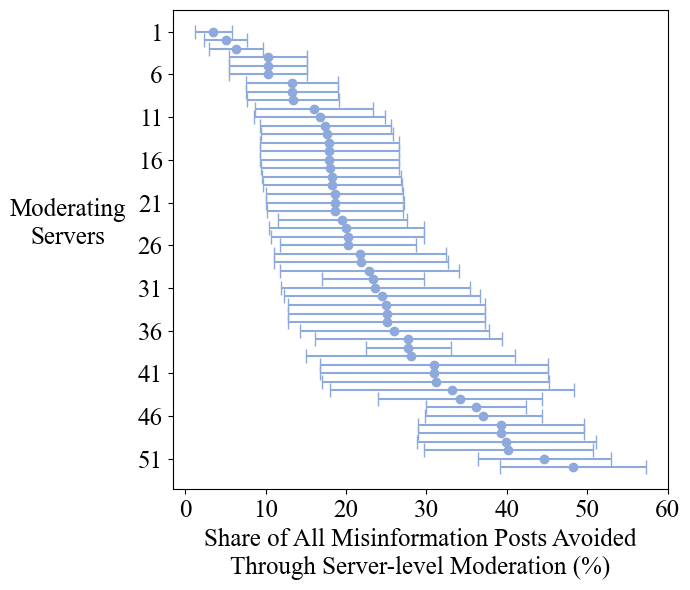

In [49]:
data = results_dict
fontsize=18

# Extract data from the dictionary
servers = list(data.keys())
values = [data[server][0] for server in servers]
errors = [data[server][1] for server in servers]

# Sort by values for better visualization
sorted_indices = np.argsort(values)
servers_sorted = [servers[i] for i in sorted_indices]
values_sorted = [values[i]*100 for i in sorted_indices]
errors_sorted = [errors[i]*100 for i in sorted_indices]

# Create the plot
plt.figure(figsize=(7, 6))
plt.errorbar(
    values_sorted, range(len(servers_sorted)), xerr=errors_sorted, fmt='o', capsize=5, label='Moderated Share',
    color='#8EA9DB'
)
# plt.axvline(x=0.5, color='red', linestyle='--', label='50% Threshold')

# Customizing the plot
plt.gca().invert_yaxis()  # Invert y-axis for readability
# Display server numbers, skipping every 5 for clarity
plt.yticks(
    range(len(servers_sorted))[::5],
    [str(i + 1) for i in range(len(servers_sorted))][::5],
    fontsize=fontsize
)
plt.xticks(fontsize=fontsize)
plt.xlabel('Share of All Misinformation Posts Avoided\nThrough Server-level Moderation (%)', fontsize=fontsize)
plt.ylabel('Moderating\nServers', rotation=0, fontsize=fontsize, labelpad=50)
# plt.title('Moderation Effectiveness Across Servers')
# plt.legend()
plt.tight_layout()

# Show the plot
plt.show()

## collateral damage

### post-level

In [50]:
# Count total rows for each instance in the original DataFrame
total_counts = toots_df['instance'].value_counts().to_dict()
total_counts

{'social.trom.tf': 10039,
 'veenus.art': 10039,
 'pl.slash.cl': 10039,
 'friendica.eskimo.com': 10039,
 'squeet.me': 10038,
 'poliverso.org': 10034,
 'fediverse.one': 10025,
 'freesoftwareextremist.com': 10000,
 'gensokyo.town': 10000,
 'ruby.social': 10000,
 'toot.funami.tech': 10000,
 'social.mochi.academy': 10000,
 'mastodos.com': 10000,
 'scalie.club': 10000,
 'social.3dots.lv': 10000,
 'mastodon.gamedev.place': 10000,
 'hexadon.net': 10000,
 'social.cu2d.com': 10000,
 'baraag.net': 10000,
 'ieji.de': 10000,
 '0w0.is': 10000,
 'wrestle.town': 10000,
 'sakurajima.moe': 10000,
 'kcmo.social': 10000,
 'vkl.world': 10000,
 'nuwasocial.com': 10000,
 'weird.autos': 10000,
 'social.ataxya.net': 10000,
 'social.am-networks.fr': 10000,
 'h4.io': 10000,
 'koreadon.com': 10000,
 'roleplayers.bub.org': 10000,
 'kemonodon.club': 10000,
 'toot.lv': 10000,
 'mstdn.takuya-a.net': 10000,
 'unstable.icu': 10000,
 'wxw.moe': 10000,
 'kollegin.eu': 10000,
 'vocalounge.cafe': 10000,
 'mastodon.energy':

In [51]:
damage_results_dict = dict()

In [52]:
for moderated_server in misinfo_moderated_list:
    if moderated_server in total_counts:
        print(moderated_server)
        tmp_df = toots_df.loc[toots_df['instance']==moderated_server]
        share_list = list()
        for threshold in thresholds:
            share_list.append(tmp_df.loc[(tmp_df['hause_quality'] > threshold)|(tmp_df['hause_quality'].isnull())].shape[0]/total_counts[moderated_server])
        damage_results_dict[moderated_server]= compute_average_and_ci(share_list)
    else:
        print(moderated_server, 'not in toots data')

remnant.social
social.daspr.io not in toots data
unperson.us
3zi.ru
clube.social
dingdash.com
djsumdog.com
eveningzoo.club
fosstodon.org
freeatlantis.com
hitchhiker.social
iddqd.social
leafposter.club
liberdon.com
libertynode.net not in toots data
librenet.co.za
nalocal519.social not in toots data
netz.darknight-coffee.org not in toots data
piazza.today
pkteerium.xyz
pl.psion.co
podcastindex.social
pravda.me
psyopshop.com
rebelbase.site
sheep.network
social.teci.world
theres.life not in toots data
tuusin.misono-ya.info
otr.rocks
cheeseburger.social not in toots data
brighteon.social
mastodon.staycuriousandkeepsmil.in
noagendasocial.com
social.urspringer.de not in toots data
truthsocial.co.in
dev.brighteon.social
social.hendrixgames.com not in toots data
social.unturf.com
social.luca0n.com
social.kd0ioe.com
social.yaofur.com not in toots data
social.ghost7.com
social.fedida.com not in toots data
social.tpapak.com
social.0x2142.com not in toots data
social.neurer.com not in toots data
so

In [53]:
len(misinfo_moderated_list)

75

In [54]:
len(damage_results_dict)

52

In [55]:
for key in damage_results_dict:
    if key in results_dict:
        print(key)

In [56]:
for key in results_dict:
    if key in damage_results_dict:
        print(key)

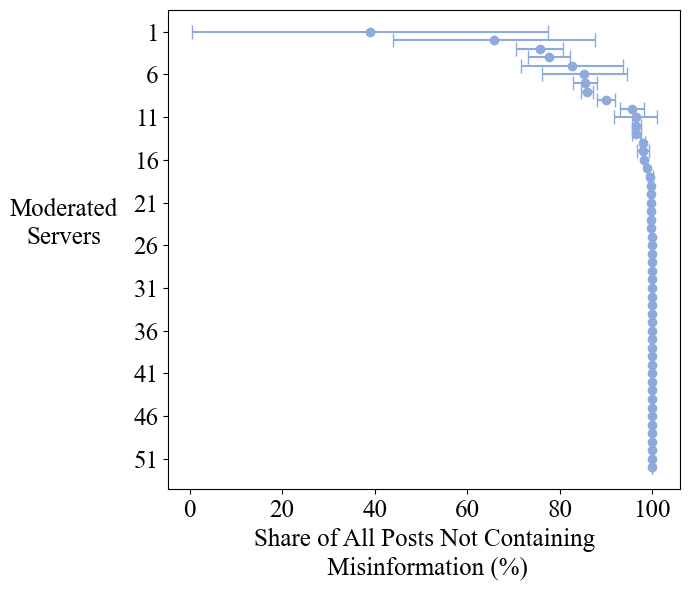

In [57]:

data = damage_results_dict
fontsize=18

# Extract data from the dictionary
servers = list(data.keys())
values = [data[server][0] for server in servers]
errors = [data[server][1] for server in servers]

# Sort by values for better visualization
sorted_indices = np.argsort(values)
servers_sorted = [servers[i] for i in sorted_indices]
values_sorted = [values[i]*100 for i in sorted_indices]
errors_sorted = [errors[i]*100 for i in sorted_indices]

# Create the plot
plt.figure(figsize=(7, 6))
plt.errorbar(
    values_sorted, range(len(servers_sorted)), xerr=errors_sorted, fmt='o', capsize=5, label='Moderated Share',
    color='#8EA9DB'
)
# plt.axvline(x=0.5, color='red', linestyle='--', label='50% Threshold')

# Customizing the plot
plt.gca().invert_yaxis()  # Invert y-axis for readability
# Display server numbers, skipping every 5 for clarity
plt.yticks(
    range(len(servers_sorted))[::5],
    [str(i + 1) for i in range(len(servers_sorted))][::5],
    fontsize=fontsize
)
plt.xticks(fontsize=fontsize)
plt.xlabel('Share of All Posts Not Containing\n Misinformation (%)', fontsize=fontsize)
plt.ylabel('Moderated\nServers', rotation=0, fontsize=fontsize, labelpad=50)
# plt.title('Moderation Effectiveness Across Servers')
# plt.legend()
plt.tight_layout()

# Show the plot
plt.show()

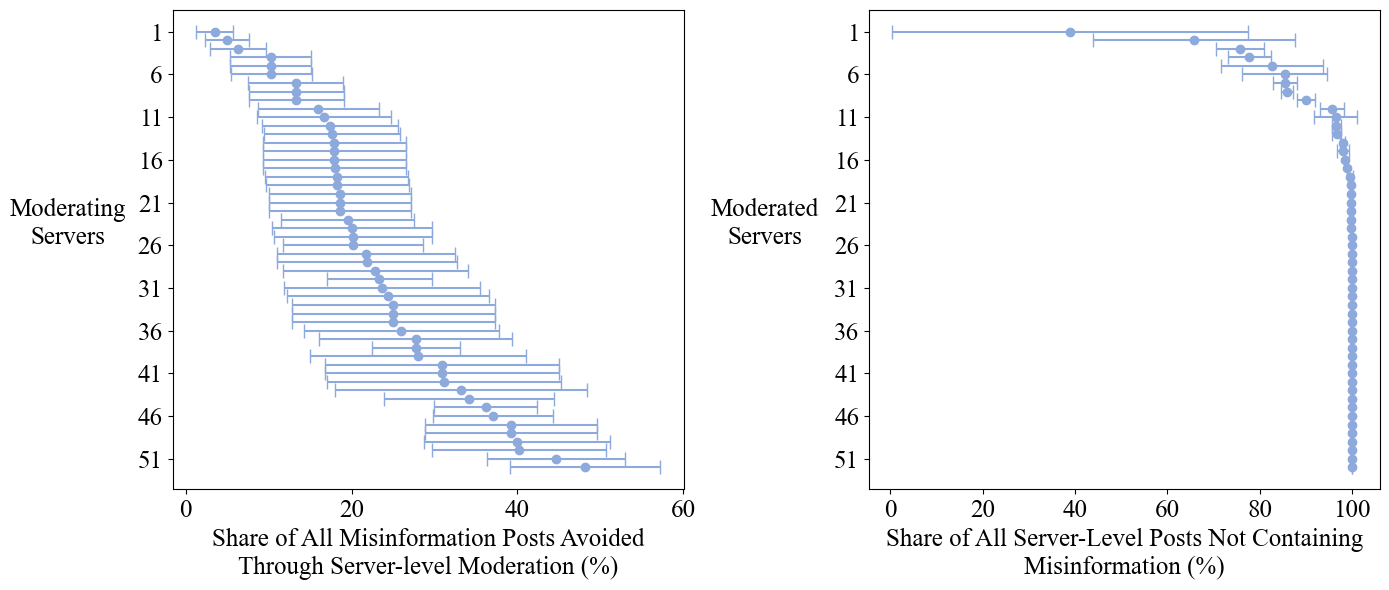

In [58]:
import matplotlib.pyplot as plt
import numpy as np

fontsize = 18

# First dataset
data1 = results_dict

# Extract and sort data
servers1 = list(data1.keys())
values1 = [data1[server][0] for server in servers1]
errors1 = [data1[server][1] for server in servers1]

sorted_indices1 = np.argsort(values1)
servers_sorted1 = [servers1[i] for i in sorted_indices1]
values_sorted1 = [values1[i] * 100 for i in sorted_indices1]
errors_sorted1 = [errors1[i] * 100 for i in sorted_indices1]

# Second dataset
data2 = damage_results_dict

# Extract and sort data
servers2 = list(data2.keys())
values2 = [data2[server][0] for server in servers2]
errors2 = [data2[server][1] for server in servers2]

sorted_indices2 = np.argsort(values2)
servers_sorted2 = [servers2[i] for i in sorted_indices2]
values_sorted2 = [values2[i] * 100 for i in sorted_indices2]
errors_sorted2 = [errors2[i] * 100 for i in sorted_indices2]

# Create a figure with two horizontal subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot the first subplot
axes[0].errorbar(
    values_sorted1, range(len(servers_sorted1)), xerr=errors_sorted1, fmt='o', capsize=5, color='#8EA9DB'
)
axes[0].invert_yaxis()  # Invert y-axis for readability
axes[0].set_yticks(range(len(servers_sorted1))[::5])
axes[0].set_yticklabels([str(i + 1) for i in range(len(servers_sorted1))][::5], fontsize=fontsize)
axes[0].tick_params(axis='x', labelsize=fontsize)
axes[0].set_xlabel('Share of All Misinformation Posts Avoided\nThrough Server-level Moderation (%)', fontsize=fontsize)
axes[0].set_ylabel('Moderating\nServers', rotation=0, fontsize=fontsize, labelpad=50)

# Plot the second subplot
axes[1].errorbar(
    values_sorted2, range(len(servers_sorted2)), xerr=errors_sorted2, fmt='o', capsize=5, color='#8EA9DB'
)
axes[1].invert_yaxis()  # Invert y-axis for readability
axes[1].set_yticks(range(len(servers_sorted2))[::5])
axes[1].set_yticklabels([str(i + 1) for i in range(len(servers_sorted2))][::5], fontsize=fontsize)
axes[1].tick_params(axis='x', labelsize=fontsize)
axes[1].set_xlabel('Share of All Server-Level Posts Not Containing\nMisinformation (%)', fontsize=fontsize)
axes[1].set_ylabel('Moderated\nServers', rotation=0, fontsize=fontsize, labelpad=50)

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

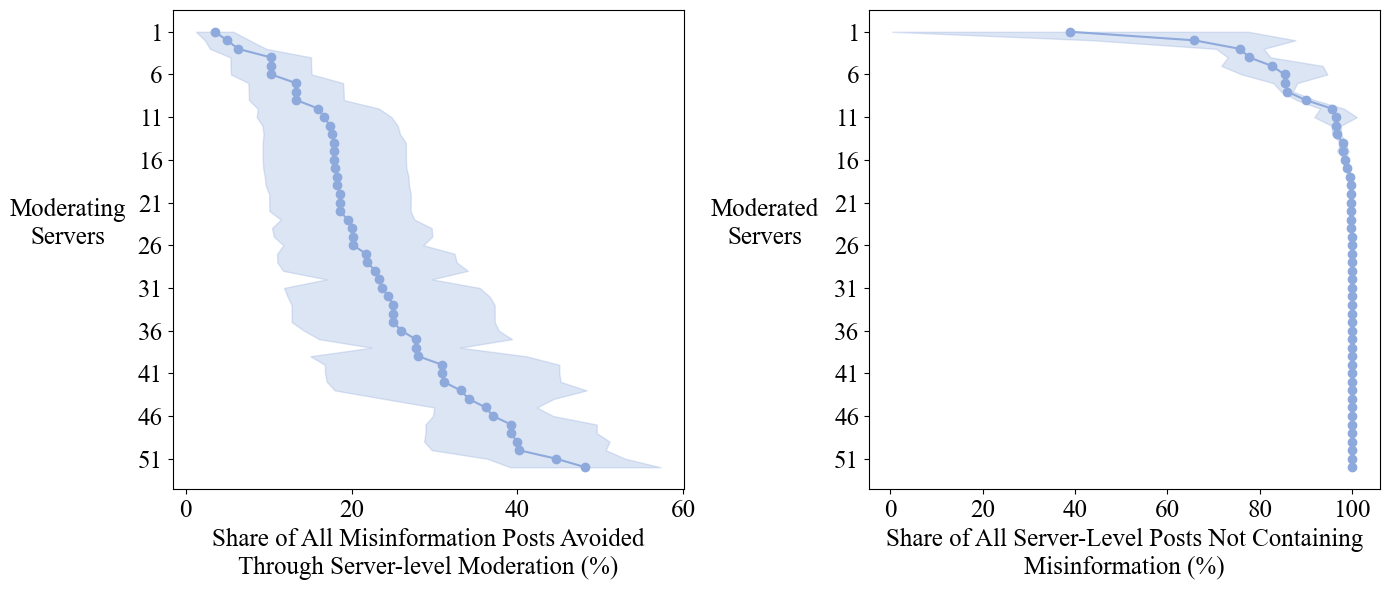

In [59]:
fontsize = 18

# First dataset
data1 = results_dict

# Extract and sort data
servers1 = list(data1.keys())
values1 = [data1[server][0] for server in servers1]
errors1 = [data1[server][1] for server in servers1]

sorted_indices1 = np.argsort(values1)
servers_sorted1 = [servers1[i] for i in sorted_indices1]
values_sorted1 = [values1[i] * 100 for i in sorted_indices1]
errors_sorted1 = [errors1[i] * 100 for i in sorted_indices1]

# Calculate upper and lower bounds of the CI for the first dataset
lower_bound1 = [v - e for v, e in zip(values_sorted1, errors_sorted1)]
upper_bound1 = [v + e for v, e in zip(values_sorted1, errors_sorted1)]

# Second dataset
data2 = damage_results_dict

# Extract and sort data
servers2 = list(data2.keys())
values2 = [data2[server][0] for server in servers2]
errors2 = [data2[server][1] for server in servers2]

sorted_indices2 = np.argsort(values2)
servers_sorted2 = [servers2[i] for i in sorted_indices2]
values_sorted2 = [values2[i] * 100 for i in sorted_indices2]
errors_sorted2 = [errors2[i] * 100 for i in sorted_indices2]

# Calculate upper and lower bounds of the CI for the second dataset
lower_bound2 = [v - e for v, e in zip(values_sorted2, errors_sorted2)]
upper_bound2 = [v + e for v, e in zip(values_sorted2, errors_sorted2)]

# Create a figure with two horizontal subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot the first subplot
axes[0].plot(values_sorted1, range(len(servers_sorted1)), 'o-', color='#8EA9DB')
axes[0].fill_betweenx(
    range(len(servers_sorted1)),
    lower_bound1,
    upper_bound1,
    color='#8EA9DB',
    alpha=0.3,
    label='95% CI'
)
axes[0].invert_yaxis()  # Invert y-axis for readability
axes[0].set_yticks(range(len(servers_sorted1))[::5])
axes[0].set_yticklabels([str(i + 1) for i in range(len(servers_sorted1))][::5], fontsize=fontsize)
axes[0].tick_params(axis='x', labelsize=fontsize)
axes[0].set_xlabel('Share of All Misinformation Posts Avoided\nThrough Server-level Moderation (%)', fontsize=fontsize)
axes[0].set_ylabel('Moderating\nServers', rotation=0, fontsize=fontsize, labelpad=50)

# Plot the second subplot
axes[1].plot(values_sorted2, range(len(servers_sorted2)), 'o-', color='#8EA9DB')
axes[1].fill_betweenx(
    range(len(servers_sorted2)),
    lower_bound2,
    upper_bound2,
    color='#8EA9DB',
    alpha=0.3,
    label='95% CI'
)
axes[1].invert_yaxis()  # Invert y-axis for readability
axes[1].set_yticks(range(len(servers_sorted2))[::5])
axes[1].set_yticklabels([str(i + 1) for i in range(len(servers_sorted2))][::5], fontsize=fontsize)
axes[1].tick_params(axis='x', labelsize=fontsize)
axes[1].set_xlabel('Share of All Server-Level Posts Not Containing\nMisinformation (%)', fontsize=fontsize)
axes[1].set_ylabel('Moderated\nServers', rotation=0, fontsize=fontsize, labelpad=50)

# Adjust layout and display the plot
plt.tight_layout()
plt.show()


# Hate Speech

In [60]:
annotation_df = pd.read_csv(join(BASE_DIR, 'server_level_moderation', 'annotated.csv'))
annotation_df.head()

,reason,count,be_nice,dick,hate_speech,covenant,harassment,CP/pedophilia,zoophilia,NSFW,...,imported,mutual_block,free_speech,unsupported_language,nationality,gab,lack_moderation,anti_ccp,pleroma,evade_moderation
0,reason not available,78699,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,8191,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,6971,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,motivo non indicado.,1346,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,grund unbekannt,1338,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [61]:
hate_reason_list = list(annotation_df.loc[annotation_df['hate_speech']==1]['reason'].unique())

In [62]:
hate_moderating_list = list(df.loc[df['reason'].isin(hate_reason_list)]['name'].unique())
hate_moderating_list

['mstdn.io',
 'toot.cat',
 'mastodon.me.uk',
 'infosec.exchange',
 'queer.party',
 'mst3k.interlinked.me',
 'mastodon.sandwich.net',
 'tooot.im',
 'mastodon.art',
 'mstdn.plus',
 'mastodon.social',
 'photog.social',
 'jubi.life',
 'assortedflotsam.com',
 'djs.social',
 'glaceon.social',
 'social.bau-ha.us',
 'mstdn.id',
 'eldritch.cafe',
 'plush.city',
 'sunbeam.city',
 'tooting.ch',
 'dice.camp',
 'polyglot.city',
 'deadinsi.de',
 'muenchen.social',
 'is.nota.live',
 'libretooth.gr',
 'pl.nudie.social',
 'www.librepunk.club',
 'ifwo.eu',
 'darmstadt.social',
 'mastodon.online',
 'sociale.network',
 'social.finkhaeuser.de',
 'nrw.social',
 'c.im',
 'ludosphere.fr',
 'nixnet.social',
 'transmom.love',
 'my0.net',
 'hessen.social',
 'pagan.plus',
 'dragonscave.space',
 'puntarella.party',
 'chilemasto.casa',
 'grandma.space',
 'sueden.social',
 'tkz.one',
 'mastodon.pub.solar',
 'cheeseburger.social',
 'ailbhean.co-shaoghal.net',
 'toot.funami.tech',
 'cityofchicago.live',
 'emeraldsocia

In [63]:
len(hate_moderating_list)

279

In [64]:
hate_moderated_list = list(df.loc[df['reason'].isin(hate_reason_list)]['moderated_instance'].unique())
hate_moderated_list

['geofront.rocks',
 'nicecrew.digital',
 'poa.st',
 'spinster.xyz',
 '101010.pl',
 '1745.info',
 'annihilation.social',
 'clew.lol',
 'mastodon.la',
 'otr.rocks',
 'rebelbase.site',
 'shortstacksran.ch',
 'witches.live',
 'supernets.social',
 'fluf.club',
 'gameliberty.club',
 'iddqd.social',
 'posting.lolicon.rocks',
 'troll.cafe',
 'yggdrasil.social',
 'pl.tkammer.de',
 'asimon.org',
 'bassam.social',
 'berserker.town',
 'boymoder.biz',
 'bronyfurry.com',
 'bunnyanarchy.org',
 'calobar.club',
 'campduffel.social',
 'cawfee.club',
 'clubcyberia.co',
 'comfyboy.club',
 'crlf.ninja',
 'decayable.ink',
 'dingdash.com',
 'eientei.org',
 'endtimebelievers.com',
 'eveningzoo.club',
 'fed.alteregocreations.com',
 'fedibird.com',
 'fluffytail.org',
 'fosstodon.org',
 'freeatlantis.com',
 'froth.zone',
 'gearlandia.haus',
 'glee.li',
 'honeytree.social',
 'journa.host',
 'lain.com',
 'liberdon.com',
 'libertynode.net',
 'librosphere.fr',
 'linuxrocks.online',
 'mugicha.club',
 'needs.vodka',
 

In [65]:
hate_per_instance = pd.read_csv(join(BASE_DIR, "hate_speech", "hs_per_instance_all_toots.csv"))

In [66]:
hate_per_instance.sample(2)

,instance_id,False,True,n,hs_percent
7038,social.lond.com.br,5,0,5,0.0
2315,glassrivermedia.me,11,0,11,0.0


In [67]:
hate_per_instance["True"].sum()/hate_per_instance.n.sum()

np.float64(0.0034647266397061366)

In [68]:
hate_per_instance.sort_values(by="True", ascending=False)["True"].cumsum()/hate_per_instance["True"].sum()

5540    0.034350
1293    0.066455
9063    0.085523
5655    0.104478
6265    0.122367
          ...   
3511    1.000000
3509    1.000000
3508    1.000000
3507    1.000000
9162    1.000000
Name: True, Length: 9163, dtype: float64

In [69]:
total_hate = hate_per_instance["True"].sum()
total_hate_percent = total_hate/hate_per_instance["n"].sum()
hate_per_instance["hs_share_total_hate"] =hate_per_instance["True"]/total_hate

In [70]:
hate_per_instance[hate_per_instance["hs_share_total_hate"]>0.01]

,instance_id,False,True,n,hs_percent,hs_share_total_hate
265,amala.schwartzwelt.xyz,8593,538,9131,0.058920,0.012198
555,beefyboys.win,8919,640,9559,0.066953,0.014511
990,clubcyberia.co,8782,619,9401,0.065844,0.014035
1252,decayable.ink,8743,543,9286,0.058475,0.012312
1293,detroitriotcity.com,8496,1416,9912,0.142857,0.032105
1526,eientei.org,9271,535,9806,0.054558,0.012130
2059,freespeechextremist.com,9505,495,10000,0.049500,0.011223
2288,geofront.rocks,3891,467,4358,0.107159,0.010588
3057,leafposter.club,9047,714,9761,0.073148,0.016189
4619,merovingian.club,7289,627,7916,0.079207,0.014216


In [71]:
hate_per_instance.describe()

,False,True,n,hs_percent,hs_share_total_hate
count,9163.000000,9163.000000,9163.000000,9163.000000,9163.000000
mean,1384.439048,4.813380,1389.252428,0.002114,0.000109
std,2748.825860,38.814259,2758.423032,0.015629,0.000880
min,0.000000,0.000000,1.000000,0.000000,0.000000
25%,27.000000,0.000000,27.000000,0.000000,0.000000
50%,144.000000,0.000000,144.000000,0.000000,0.000000
75%,910.500000,1.000000,913.500000,0.000101,0.000023
max,10026.000000,1515.000000,10036.000000,1.000000,0.034350


In [72]:
hate_per_instance.sort_values(by="hs_share_total_hate", ascending=False).cumsum()["hs_share_total_hate"]


5540    0.034350
1293    0.066455
9063    0.085523
5655    0.104478
6265    0.122367
          ...   
3511    1.000000
3509    1.000000
3508    1.000000
3507    1.000000
9162    1.000000
Name: hs_share_total_hate, Length: 9163, dtype: float64

In [73]:
hate_per_instance[hate_per_instance["True"]==0].shape[0]/hate_per_instance.shape[0]

0.7474626214122012

In [74]:
hate_results_dict = dict()
for moderating_server in hate_moderating_list:
    print(moderating_server)
    moderating_df = df.loc[df['name']==moderating_server]
    moderated_list = list(moderating_df['moderated_instance'].unique())
    tmp_df = hate_per_instance.loc[hate_per_instance['instance_id'].isin(moderated_list)]
    hate_results_dict[moderating_server]= tmp_df["True"].sum()/total_hate

mstdn.io
toot.cat
mastodon.me.uk
infosec.exchange
queer.party
mst3k.interlinked.me
mastodon.sandwich.net
tooot.im
mastodon.art
mstdn.plus
mastodon.social
photog.social
jubi.life
assortedflotsam.com
djs.social
glaceon.social
social.bau-ha.us
mstdn.id
eldritch.cafe
plush.city
sunbeam.city
tooting.ch
dice.camp
polyglot.city
deadinsi.de
muenchen.social
is.nota.live
libretooth.gr
pl.nudie.social
www.librepunk.club
ifwo.eu
darmstadt.social
mastodon.online
sociale.network
social.finkhaeuser.de
nrw.social
c.im
ludosphere.fr
nixnet.social
transmom.love
my0.net
hessen.social
pagan.plus
dragonscave.space
puntarella.party
chilemasto.casa
grandma.space
sueden.social
tkz.one
mastodon.pub.solar
cheeseburger.social
ailbhean.co-shaoghal.net
toot.funami.tech
cityofchicago.live
emeraldsocial.org
urbanists.social
meow.lgbt
social.horrorhub.club
trans.house
mastodon.oliverfalvai.xyz
famichiki.jp
forked.io
freifunk.social
ohai.social
glauca.space
mstdn.party
furries.club
tiggi.es
aut.social
union.place
toot

In [75]:
hate_results_dict

{'mstdn.io': np.float64(0.06523069946718059),
 'toot.cat': np.float64(0.3592336469788006),
 'mastodon.me.uk': np.float64(0.08763178777916336),
 'infosec.exchange': np.float64(0.32511053168574994),
 'queer.party': np.float64(0.3062691304840721),
 'mst3k.interlinked.me': np.float64(0.06366625099195103),
 'mastodon.sandwich.net': np.float64(0.4358236027661263),
 'tooot.im': np.float64(0.2747987756490194),
 'mastodon.art': np.float64(0.4786532139213241),
 'mstdn.plus': np.float64(0.34007482144881535),
 'mastodon.social': np.float64(0.2775649019385557),
 'photog.social': np.float64(0.3261988436685183),
 'jubi.life': np.float64(0.44559573744473413),
 'assortedflotsam.com': np.float64(0.06917583040471602),
 'djs.social': np.float64(0.4057589842421494),
 'glaceon.social': np.float64(0.17900464799909308),
 'social.bau-ha.us': np.float64(0.33950799229112344),
 'mstdn.id': np.float64(0.024872463439519328),
 'eldritch.cafe': np.float64(0.3383970071420474),
 'plush.city': np.float64(0.3838567055889

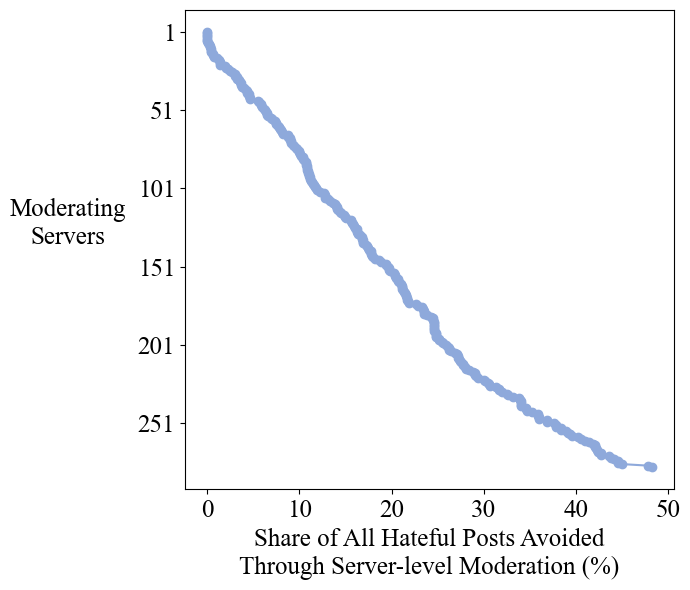

In [76]:
fontsize = 18

data = hate_results_dict
servers = list(data.keys())
values = [data[server] for server in servers]

# Sort by values for visualization
sorted_indices = np.argsort(values)
servers_sorted = [servers[i] for i in sorted_indices]
values_sorted = [values[i] * 100 for i in sorted_indices]

plt.figure(figsize=(7, 6))
plt.plot(values_sorted, range(len(servers_sorted)), 'o-', label='Moderated Share', color='#8EA9DB')

# Customizing the plot
plt.gca().invert_yaxis()  # Invert y-axis for readability
plt.yticks(
    range(len(servers_sorted))[::50],
    [str(i + 1) for i in range(len(servers_sorted))][::50],
    fontsize=fontsize
)
plt.xticks(fontsize=fontsize)
plt.xlabel('Share of All Hateful Posts Avoided\nThrough Server-level Moderation (%)', fontsize=fontsize)
plt.ylabel('Moderating\nServers', rotation=0, fontsize=fontsize, labelpad=50)
# plt.legend(fontsize=fontsize)
plt.tight_layout()

# Show the plot
plt.show()


### collateral damage

In [77]:
total_counts = hate_per_instance[['instance_id',"n"]].set_index('instance_id').to_dict()['n']
total_counts

{'0.0n.ee': 57,
 '000000420.xyz': 8,
 '0rb.it': 4,
 '0v0.ch': 9,
 '0verti.me': 102,
 '0w0.is': 9954,
 '0x3c.pl': 902,
 '0x50.ch': 1,
 '0xee.io': 125,
 '101010.pl': 9459,
 '10211104.fedicity.net': 8,
 '103.social': 64,
 '10mb.social': 194,
 '1210.nl': 51,
 '1435.es': 17,
 '15-15-15.social': 195,
 '1745.info': 163,
 '184.im': 3,
 '19marbles.org': 452,
 '1password.social': 108,
 '1uca.com': 10000,
 '23.illuminati.org': 684,
 '27origin.com': 142,
 '280562.com': 19,
 '285936586.masto.host': 9981,
 '2bit.social': 2,
 '2c.taoetc.org': 244,
 '2m.cutls.com': 1912,
 '2pxnl.de': 342,
 '30d.org': 2,
 '3252.robertwgehl.org': 10,
 '333thats33s.cc': 129,
 '338338.xyz': 182,
 '3615.computer': 1770,
 '366.koyomi.online': 1753,
 '386898.xyz': 36,
 '39sounds.net': 1183,
 '3dp.chat': 4282,
 '3rdwall.net': 5,
 '3v.is': 315,
 '3zi.ru': 2360,
 '404.inexist.club': 9900,
 '430022.xyz': 11,
 '4458644.xyz': 19,
 '4bear.com': 8228,
 '4four.org': 39,
 '500plus.slavistapl.eu.org': 196,
 '5280.city': 106,
 '5evo.fan

In [78]:
hate_damage_results_dict = hate_per_instance[hate_per_instance["instance_id"].isin(hate_moderated_list)][['instance_id',"hs_percent"]].set_index('instance_id').to_dict()['hs_percent']
hate_damage_results_dict

{'101010.pl': 0.0024315466751242,
 '1745.info': 0.0,
 'akko.disqordia.space': 0.0143346837020878,
 'amala.schwartzwelt.xyz': 0.0589201620852042,
 'animalliberation.social': 0.0015637216575449,
 'annihilation.social': 0.0211480362537764,
 'asimon.org': 0.025,
 'awwter.online': 0.0149253731343283,
 'bassam.social': 0.0233044517478338,
 'beefyboys.win': 0.0669526101056595,
 'bikeshed.party': 0.0035928143712574,
 'bkcastle.net': 0.0,
 'blob.cat': 0.0033395950740972,
 'boymoder.biz': 0.0503306392358559,
 'brighteon.social': 0.011839814277423,
 'bunnyanarchy.org': 0.0110987791342952,
 'c.im': 0.0031370908710655,
 'calobar.club': 0.2068511198945981,
 'campduffel.social': 0.0013157894736842,
 'cawfee.club': 0.0240549828178694,
 'clew.lol': 0.0375752543076603,
 'clubcyberia.co': 0.0658440591426443,
 'cock.fish': 0.0,
 'comp.lain.la': 0.0164102564102564,
 'decayable.ink': 0.0584751238423433,
 'detroitriotcity.com': 0.1428571428571428,
 'dev.brighteon.social': 0.0188935539639417,
 'dingdash.com':

In [79]:
len(hate_damage_results_dict)

196

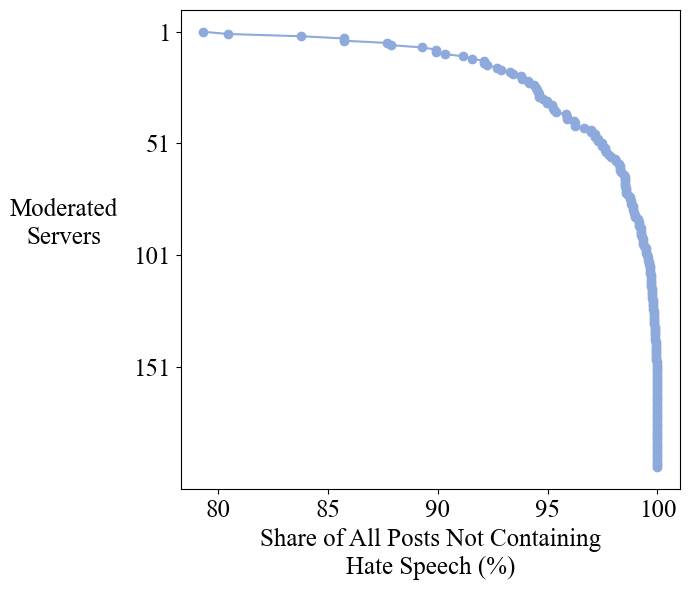

In [80]:
fontsize = 18

data = hate_damage_results_dict
servers = list(data.keys())
values = [1- data[server] for server in servers] # want to plot share of posts not-containing HS
# Sort by values for better visualization
sorted_indices = np.argsort(values)
servers_sorted = [servers[i] for i in sorted_indices]
values_sorted = [values[i] * 100 for i in sorted_indices]

plt.figure(figsize=(7, 6))
plt.plot(values_sorted, range(len(servers_sorted)), 'o-', label='Moderated Share', color='#8EA9DB')


# Customizing the plot
plt.gca().invert_yaxis()  # Invert y-axis for readability
plt.yticks(
    range(len(servers_sorted))[::50],
    [str(i + 1) for i in range(len(servers_sorted))][::50],
    fontsize=fontsize
)
plt.xticks(fontsize=fontsize)
plt.xlabel('Share of All Posts Not Containing\nHate Speech (%)', fontsize=fontsize)
plt.ylabel('Moderated\nServers', rotation=0, fontsize=fontsize, labelpad=50)
# plt.legend(fontsize=fontsize)
plt.tight_layout()

# Show the plot
plt.show()

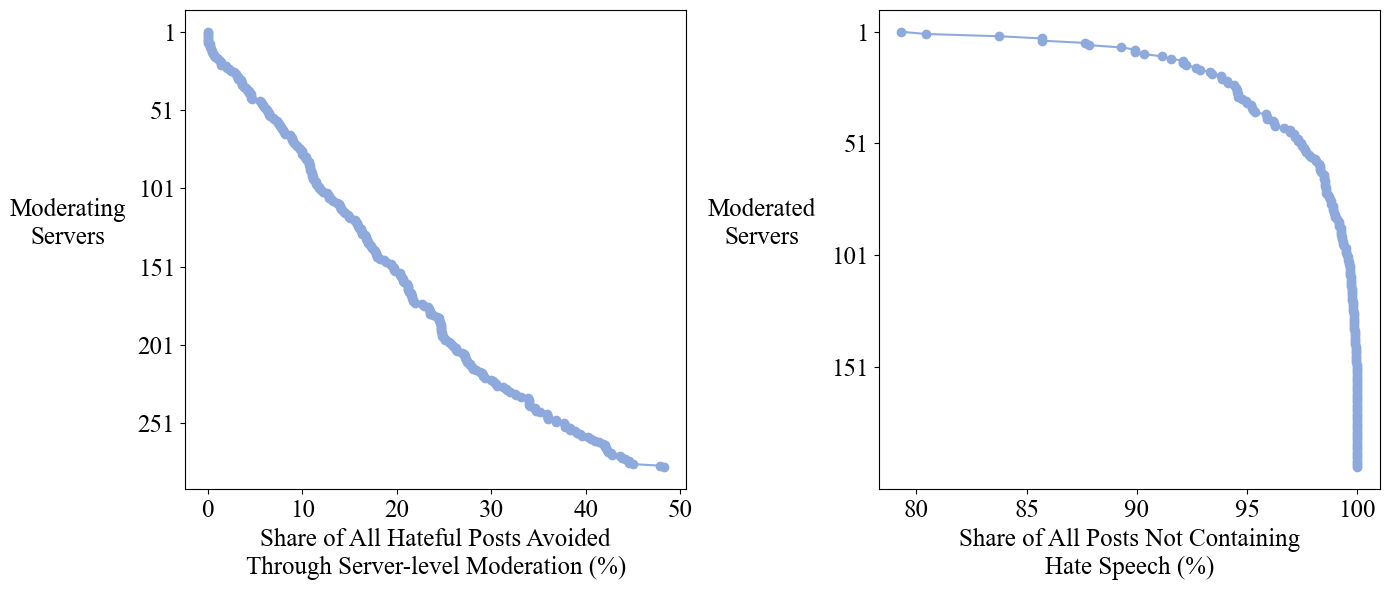

In [81]:
fontsize = 18

# First dataset (Hate results)
data1 = hate_results_dict

# Extract and sort data
servers1 = list(data1.keys())
values1 = [data1[server] for server in servers1]

sorted_indices1 = np.argsort(values1)
servers_sorted1 = [servers1[i] for i in sorted_indices1]
values_sorted1 = [values1[i] * 100 for i in sorted_indices1]

# Second dataset (Damage results)
data2 = hate_damage_results_dict
servers2 = list(data2.keys())
values2 = [1- data2[server] for server in servers2]

sorted_indices2 = np.argsort(values2)
servers_sorted2 = [servers2[i] for i in sorted_indices2]
values_sorted2 = [values2[i] * 100 for i in sorted_indices2]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot the first subplot
axes[0].plot(values_sorted1, range(len(servers_sorted1)), 'o-', label='Moderated Share', color='#8EA9DB')
axes[0].invert_yaxis()  # Invert y-axis for readability
axes[0].set_yticks(range(len(servers_sorted1))[::50])
axes[0].set_yticklabels([str(i + 1) for i in range(len(servers_sorted1))][::50], fontsize=fontsize)
axes[0].tick_params(axis='x', labelsize=fontsize)
axes[0].set_xlabel('Share of All Hateful Posts Avoided\nThrough Server-level Moderation (%)', fontsize=fontsize)
axes[0].set_ylabel('Moderating\nServers', rotation=0, fontsize=fontsize, labelpad=50)

# Plot the second subplot
axes[1].plot(values_sorted2, range(len(servers_sorted2)), 'o-', label='Moderated Share', color='#8EA9DB')
axes[1].invert_yaxis()  # Invert y-axis for readability
axes[1].set_yticks(range(len(servers_sorted2))[::50])
axes[1].set_yticklabels([str(i + 1) for i in range(len(servers_sorted2))][::50], fontsize=fontsize)
axes[1].tick_params(axis='x', labelsize=fontsize)
axes[1].set_xlabel('Share of All Posts Not Containing\nHate Speech (%)', fontsize=fontsize)
axes[1].set_ylabel('Moderated\nServers', rotation=0, fontsize=fontsize, labelpad=50)

# Adjust layout and display the plot
plt.tight_layout()
plt.show()


In [82]:
len(data1)

279

In [83]:
len(data2)

196

## final plot

In [84]:
def process_misinfo_data(data):
    servers = list(data.keys())
    values = [data[server][0] for server in servers]
    errors = [data[server][1] for server in servers]
    sorted_indices = np.argsort(values)
    servers_sorted = [servers[i] for i in sorted_indices]
    values_sorted = [values[i] * 100 for i in sorted_indices]
    errors_sorted = [errors[i] * 100 for i in sorted_indices]
    lower_bound = [v - e for v, e in zip(values_sorted, errors_sorted)]
    upper_bound = [v + e for v, e in zip(values_sorted, errors_sorted)]
    return servers_sorted, values_sorted, errors_sorted, lower_bound, upper_bound

def process_hs_data(data, non_hate=False):
    servers = list(data.keys())
    if non_hate:
        values = [1- data[server] for server in servers]
    else:
        values = [data[server] for server in servers]
    sorted_indices = np.argsort(values)
    servers_sorted = [servers[i] for i in sorted_indices]
    values_sorted = [values[i] * 100 for i in sorted_indices]
    return servers_sorted, values_sorted

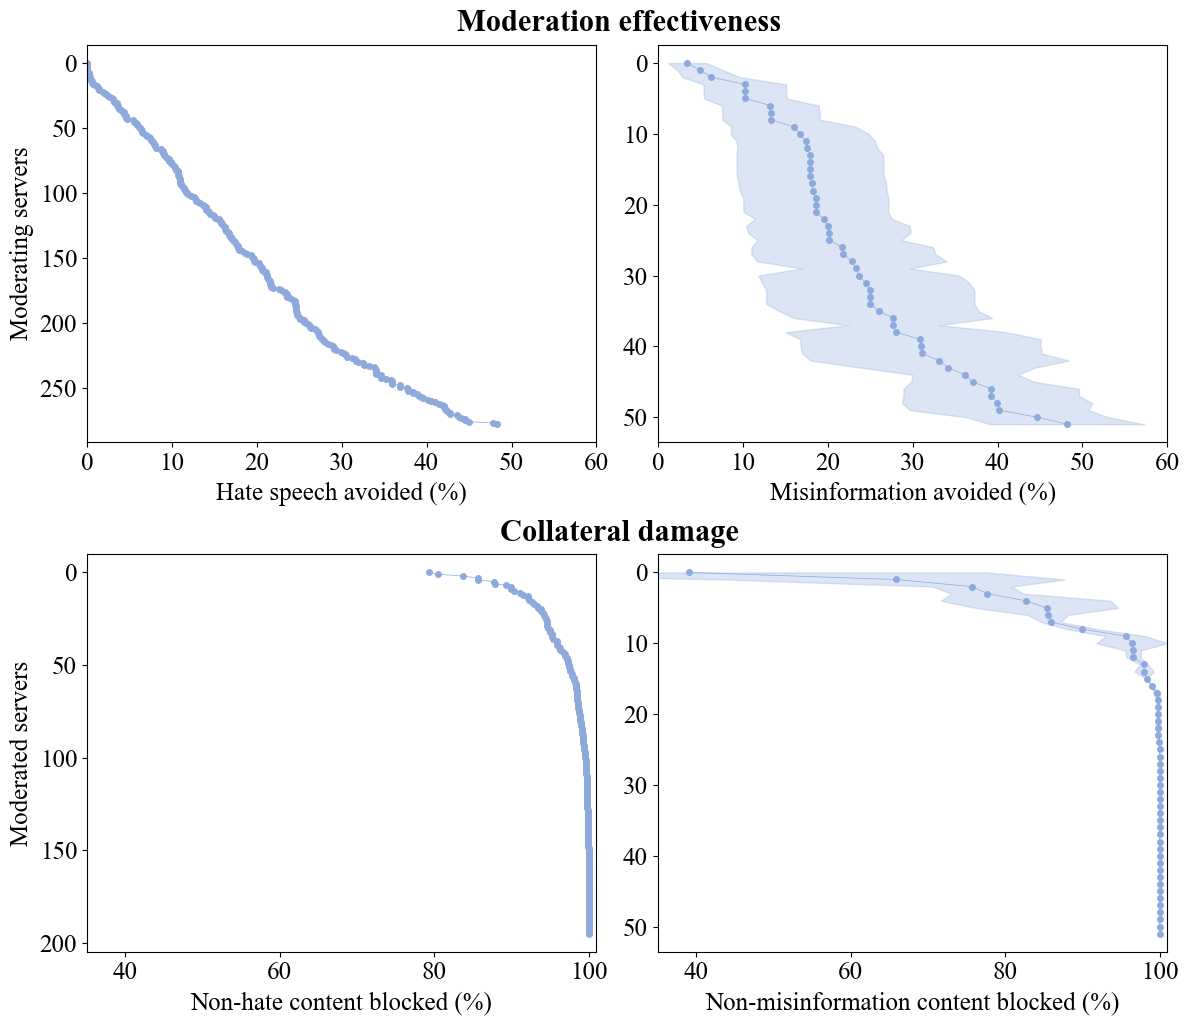

In [85]:
fontsize = 18
color = '#8EA9DB'
markersize=4
linewidth=0.5
# Data
data_hate = hate_results_dict
data_damage_hate = hate_damage_results_dict
data_misinfo = results_dict
data_damage_misinfo = damage_results_dict

# Process data
servers_hate, values_hate = process_hs_data(data_hate)
servers_damage_hate, values_damage_hate = process_hs_data(data_damage_hate, non_hate=True)
servers_misinfo, values_misinfo, errors_misinfo, lower_misinfo, upper_misinfo = process_misinfo_data(data_misinfo)
servers_damage_misinfo, values_damage_misinfo, errors_damage_misinfo, lower_damage_misinfo, upper_damage_misinfo = process_misinfo_data(data_damage_misinfo)

# Create a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Top row: Effectiveness 

axes[0, 0].plot(values_hate, range(len(servers_hate)), 'o-', label='Moderated Share', color=color, markersize=markersize, linewidth=linewidth)
axes[0, 0].invert_yaxis()
# axes[0, 0].set_xlabel('Hateful posts avoided\nvia server-level moderation (%)', fontsize=fontsize)
axes[0, 0].set_ylabel('Moderating servers', fontsize=fontsize)
axes[0, 0].tick_params(axis='x', labelsize=fontsize)
axes[0, 0].tick_params(axis='y', labelsize=fontsize)
axes[0, 0].set_xlim(0, 60)
axes[0, 0].set_xlabel('Hate speech avoided (%)', fontsize=fontsize)

# Add text to the left of the y label

axes[0, 1].plot(values_misinfo, range(len(servers_misinfo)), 'o-', label='Moderated Share', color=color, markersize=markersize, linewidth=linewidth)
axes[0, 1].fill_betweenx(range(len(servers_misinfo)), lower_misinfo, upper_misinfo, color='#8EA9DB', alpha=0.3, label='95% CI')
axes[0, 1].invert_yaxis()
axes[0, 1].tick_params(axis='x', labelsize=fontsize)
axes[0, 1].tick_params(axis='y', labelsize=fontsize)
axes[0, 1].set_xlim(0, 60)
axes[0, 1].set_xlabel('Misinformation avoided (%)', fontsize=fontsize)


# Bottom row: Damage

axes[1, 0].plot(values_damage_hate, range(len(servers_damage_hate)), 'o-', label='Moderated Share', color=color, markersize=markersize, linewidth=linewidth)
axes[1, 0].invert_yaxis()
# axes[0, 1].set_xlabel('Non-hateful posts affected by moderation (%)', fontsize=fontsize)
axes[1, 0].set_ylabel('Moderated servers', fontsize=fontsize)
axes[1, 0].tick_params(axis='x', labelsize=fontsize)
axes[1, 0].tick_params(axis='y', labelsize=fontsize)
axes[1, 0].set_xlim(35, 101)
axes[1, 0].set_xlabel('Non-hate content blocked (%)', fontsize=fontsize)



# Add text to the left of the y label

axes[1, 1].plot(values_damage_misinfo, range(len(servers_damage_misinfo)), 'o-', label='Moderated Share', color=color, markersize=markersize, linewidth=linewidth)
axes[1, 1].fill_betweenx(range(len(servers_damage_misinfo)), lower_damage_misinfo, upper_damage_misinfo, color='#8EA9DB', alpha=0.3, label='95% CI')
axes[1, 1].invert_yaxis()
axes[1, 1].set_xlabel('Non-misinformation content blocked (%)', fontsize=fontsize)
axes[1, 1].tick_params(axis='x', labelsize=fontsize)
axes[1, 1].tick_params(axis='y', labelsize=fontsize)
axes[1, 1].set_xlim(35, 101)


# Row headers
fig.text(0.52, 1.02, "Moderation effectiveness", ha="center", va="top", fontsize=fontsize+4, fontweight="bold")
fig.text(0.52, 0.51, "Collateral damage", ha="center", va="top", fontsize=fontsize+4, fontweight="bold")

fig.tight_layout(h_pad=3.5, w_pad=1)


# Show plot
plt.savefig('figures/effectiveness_damage.png', bbox_inches="tight", dpi=300)

## Additional stats

### Misinfo

In [86]:
# share of misinfo posts per server
misinfo_per_server_low = (
    toots_df
    .groupby("instance")["hause_quality"]
    .apply(lambda x: (x < 0.2).mean())
)

misinfo_per_server_high = (
    toots_df
    .groupby("instance")["hause_quality"]
    .apply(lambda x: (x < 0.5).mean())
)


In [87]:
prevalences = []
for t in [0.2, 0.3, 0.4, 0.5]:
    prevalences.append(toots_df[toots_df["hause_quality"]<t].shape[0]/toots_df.shape[0])

In [88]:
np.mean(prevalences)

np.float64(0.0023613740708269357)

In [89]:
toots_df[toots_df["hause_quality"]<0.2].shape[0]/toots_df.shape[0]


0.0005608534195409151

In [90]:
misinfo_per_server_low.describe()

count    10157.000000
mean         0.000351
std          0.005992
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          0.377358
Name: hause_quality, dtype: float64

In [91]:
misinfo_per_server_high.describe()

count    10157.000000
mean         0.002194
std          0.024703
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          0.954363
Name: hause_quality, dtype: float64

In [92]:
# number of those in the mdoerated list
misinfo_per_server_low[misinfo_per_server_low.index.isin(damage_results_dict.keys())].shape


(52,)

In [93]:
misinfo_per_server_low[misinfo_per_server_low.index.isin(damage_results_dict.keys())].describe()

count    52.000000
mean      0.011965
std       0.032465
min       0.000000
25%       0.000000
50%       0.000000
75%       0.001869
max       0.133200
Name: hause_quality, dtype: float64

In [94]:
# factor
misinfo_per_server_low[misinfo_per_server_low.index.isin(damage_results_dict.keys())].mean()/misinfo_per_server_low.mean()

np.float64(34.08313696058306)

In [95]:
(misinfo_per_server_low==0).sum()/len(misinfo_per_server_low)

np.float64(0.9712513537461849)

In [96]:
(misinfo_per_server_high==0).sum()/len(misinfo_per_server_high)


np.float64(0.8664960126021463)

In [97]:
misinfo_per_server_low[(misinfo_per_server_low.index.isin(damage_results_dict.keys())) & (misinfo_per_server_low==0)].shape

(34,)

### Hate

In [98]:
hate_per_instance["hs_percent"].describe()

count    9163.000000
mean        0.002114
std         0.015629
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000101
max         1.000000
Name: hs_percent, dtype: float64

In [99]:
hate_per_instance[hate_per_instance["instance_id"].isin(hate_damage_results_dict.keys())]["hs_percent"].describe()

count    196.000000
mean       0.021900
std        0.036032
min        0.000000
25%        0.000441
50%        0.005216
75%        0.027027
max        0.206851
Name: hs_percent, dtype: float64

In [100]:
hate_per_instance[hate_per_instance["instance_id"].isin(hate_damage_results_dict.keys())]["hs_percent"].mean()/hate_per_instance["hs_percent"].mean()

np.float64(10.360278928402458)

In [101]:
# percentage of servers with no hate
len(hate_per_instance[hate_per_instance["True"]==0])/len(hate_per_instance)

0.7474626214122012

In [102]:
# absolute number of moderated servers with no hate posts
hate_per_instance[(hate_per_instance["True"]==0) & (hate_per_instance["instance_id"].isin(hate_damage_results_dict.keys()))].shape[0]

42

In [103]:
# percentage of moderated servers with no hate posts
hate_per_instance[(hate_per_instance["True"]==0) & (hate_per_instance["instance_id"].isin(hate_damage_results_dict.keys()))].shape[0]/hate_per_instance[hate_per_instance["instance_id"].isin(hate_damage_results_dict.keys())].shape[0]


0.21428571428571427